### How to use
1. update `config.py` with whatever u want config to be
2. reload kernel
3. run cell below to run training pass
4. plot some shit
5. cry because results suck

In [1]:
from pipeline.train import run_training

lers, loss, total_steps = run_training()

/home/carsonab/code/school/research-assistant/code/pipeline/train.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  encoder = nn.TransformerEncoder(nn.TransformerEncoderLayer(**encoder_params), num_layers=L)   # consider norm_first if training unstable
2026-11-17 00:02:39,240 INFO     
===
TRAINING RUN: 2026-11-17_000239
2026-11-17 00:02:39,240 INFO     TRAINING CONFIG: 
{
  "encoder": {
    "d_model": 16,
    "nhead": 1,
    "dim_feedforward": 32,
    "dropout": 0.05,
    "activation": "gelu",
    "batch_first": true
  },
  "num_layers": 2,
  "batch_size": 1000,
  "warmup_ratio": 0.1,
  "lr_scheduler": "linear",
  "num_epochs": 10,
  "lr": 0.0005,
  "weight_decay": 0.01
}
2026-11-17 00:02:45,270 INFO     Beginning epoch 0
2026-11-17 00:02:45,872 INFO     entering eval at steps=0 | loss=0.8303
2026-11-17 00:02:45,873 INFO     evaluating at r=3
2026-11-17 00:02:45,931 INFO     LER: 0.9808
2026-11-17 0

Text(0.5, 0, 'eval steps')

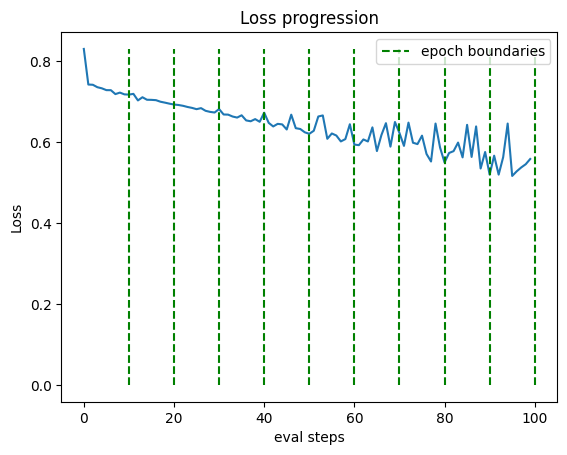

In [ ]:
from pipeline.config import load_config
cfg = load_config()
E = cfg["training"]["num_epochs"]
k = int(len(loss) / E)
epoch_boundaries = [(i+1)*k for i in range(E)]

import matplotlib.pyplot as plt
fig, ax = plt.subplots()
for r, l in loss.items():
    ax.plot(l, label=f'r={r}')

plt.vlines(epoch_boundaries, ymin=0, ymax=max(loss), linestyles='--', label="epoch boundaries", color='g')
plt.legend()
plt.title("Loss progression for each round family")
plt.ylabel("Loss")
plt.xlabel("eval steps")

Text(0.5, 1.0, 'LER for each round family as training progressed')

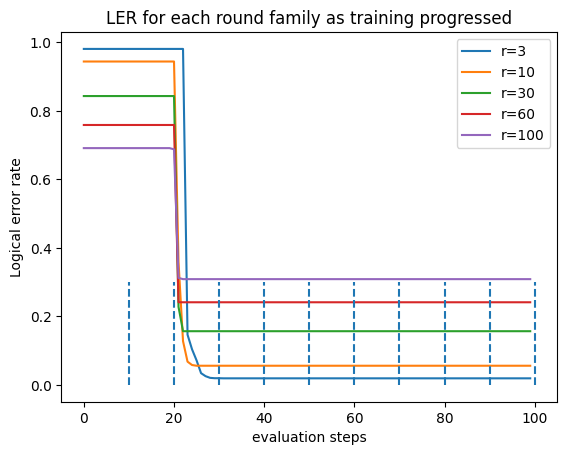

In [3]:
fig, ax = plt.subplots()
for r, l in lers.items():
    ax.plot(l, label=f'r={r}')
plt.legend()
plt.vlines(epoch_boundaries, ymin=0, ymax=0.3, linestyles='--', label="epoch boundaries")
plt.ylabel("Logical error rate")
plt.xlabel("evaluation steps")
plt.title("LER for each round family as training progressed")